# Data Collection and Preparation:

## Goal of this notebook:
- checking for missing or erroneous data (Part of "Data understanding")
- cleaning your dataset ("Data preparation")

In [1]:
import pandas as pd
import ast
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Ingesting the data
data_weather = pd.read_csv("../data/weather_burbank_airport.csv")
data_charge = pd.read_csv("../data/charging_sessions.csv")

In [3]:
# Get a brief overview about the weather data
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [4]:
# Get an overview about dtypes
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     29244 non-null  object 
 1   timestamp                29244 non-null  object 
 2   temperature              29219 non-null  float64
 3   cloud_cover              29224 non-null  float64
 4   cloud_cover_description  29224 non-null  object 
 5   pressure                 29236 non-null  float64
 6   windspeed                29158 non-null  float64
 7   precipitation            29244 non-null  float64
 8   felt_temperature         29218 non-null  float64
dtypes: float64(6), object(3)
memory usage: 2.0+ MB


In [5]:
# Get a brief overview about the charging data
data_charge.head(3)

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs
0,0,5e23b149f9af8b5fe4b973cf,2020-01-02 13:08:54+00:00,2020-01-02 19:11:15+00:00,2020-01-02 17:31:35+00:00,25.016,1_1_179_810_2020-01-02 13:08:53.870034,1,AG-3F30,1-1-179-810,America/Los_Angeles,194.0,"[{'WhPerMile': 250, 'kWhRequested': 25.0, 'mil..."
1,1,5e23b149f9af8b5fe4b973d0,2020-01-02 13:36:50+00:00,2020-01-02 22:38:21+00:00,2020-01-02 20:18:05+00:00,33.097,1_1_193_825_2020-01-02 13:36:49.599853,1,AG-1F01,1-1-193-825,America/Los_Angeles,4275.0,"[{'WhPerMile': 280, 'kWhRequested': 70.0, 'mil..."
2,2,5e23b149f9af8b5fe4b973d1,2020-01-02 13:56:35+00:00,2020-01-03 00:39:22+00:00,2020-01-02 16:35:06+00:00,6.521,1_1_193_829_2020-01-02 13:56:35.214993,1,AG-1F03,1-1-193-829,America/Los_Angeles,344.0,"[{'WhPerMile': 400, 'kWhRequested': 8.0, 'mile..."


In [6]:
# Get an overview about dtypes
data_charge.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66450 entries, 0 to 66449
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        66450 non-null  int64  
 1   id                66450 non-null  object 
 2   connectionTime    66450 non-null  object 
 3   disconnectTime    66450 non-null  object 
 4   doneChargingTime  62362 non-null  object 
 5   kWhDelivered      66450 non-null  float64
 6   sessionID         66450 non-null  object 
 7   siteID            66450 non-null  int64  
 8   spaceID           66450 non-null  object 
 9   stationID         66450 non-null  object 
 10  timezone          66450 non-null  object 
 11  userID            49187 non-null  float64
 12  userInputs        49187 non-null  object 
dtypes: float64(2), int64(2), object(9)
memory usage: 6.6+ MB


# Parse data

In [7]:
# Parse the datetime
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])
data_charge["doneChargingTime"] = pd.to_datetime(data_charge["doneChargingTime"])

In [8]:
# Check the location
data_charge["timezone"].unique()

array(['America/Los_Angeles'], dtype=object)

### => Since the time timezone is 'America/Los_Angeles' but the data description states that the data is in UTC, we have have to convert it.

In [9]:
# Convert timezone

data_charge["connectionTime"] = data_charge["connectionTime"].dt.tz_convert("America/Los_Angeles")
data_charge["disconnectTime"] = data_charge["disconnectTime"].dt.tz_convert("America/Los_Angeles")
data_charge["doneChargingTime"] = data_charge["doneChargingTime"].dt.tz_convert(
    "America/Los_Angeles"
)

# Check for duplicates

In [10]:
# Find and remove duplicates
print(f"Original length of the dataset: {len(data_charge)}")
print(f'Number of unique ids: {data_charge["id"].unique().__len__()}')
print(f'Number of duplicated ids: {data_charge[data_charge["id"].duplicated()].__len__()}')
print(
    f'Number of duplicated session ids: {data_charge[data_charge["sessionID"].duplicated()].__len__()}'
)

# Drop duplicates:
data_charge = data_charge.drop_duplicates(subset=["id"], keep="first")
print(f"Length of the dataset after droping the duplicates: {len(data_charge)}")

Original length of the dataset: 66450
Number of unique ids: 65037
Number of duplicated ids: 1413
Number of duplicated session ids: 1413
Length of the dataset after droping the duplicates: 65037


# Check for null values

In [11]:
# Find null records
data_charge.isnull().sum()

Unnamed: 0              0
id                      0
connectionTime          0
disconnectTime          0
doneChargingTime     4087
kWhDelivered            0
sessionID               0
siteID                  0
spaceID                 0
stationID               0
timezone                0
userID              17215
userInputs          17215
dtype: int64

## Insights:
1) There seems to be a lot of null values for userID and userInputs, but as they are optional attributes in the dataset, we do not need to drop them. However, we need to be aware that there will be a lot of null values when we work with these attributes.

2) There are also a lot of null values for doneChargingTime. We assume that the 4087 records with a NaN value in the doneChargingTime column are caused by the EV owner disconnecting the charger before the EV is fully charged. Our assumption would be supported if there are very few records having the same disconnect and done charging time.

In [12]:
# Check if disconnect time == doneChargingTime
matching_records = data_charge[data_charge["doneChargingTime"] == data_charge["disconnectTime"]]
len(matching_records)

5

There seem to be very few records that have the same Disconnect and doneChargingTime.

As we need the end of charge information for future feature development and doneChargingTime does not capture this information if the charger is disconnected before full charge, we create the endChargingTime feature:

In [13]:
# Add a column "endChargingTime" that holds the time when charging ended (doneChargingTime or disconnectTime if the doneChargingTime was null)
data_charge["endChargingTime"] = data_charge["doneChargingTime"].fillna(
    data_charge["disconnectTime"]
)
data_charge["endChargingTime"].isnull().sum()

0

In [15]:
# Check the amount of kwh charged if the done charging time is null to avoid problems of the station
data_charge[data_charge["doneChargingTime"].isnull()]["kWhDelivered"].quantile(
    np.linspace(0.05, 1, 19, 0), "lower"
)

0.05     0.998
0.10     2.454
0.15     3.806
0.20     4.876
0.25     5.778
0.30     6.491
0.35     7.407
0.40     8.413
0.45     9.680
0.50    10.890
0.55    12.009
0.60    13.048
0.65    14.213
0.70    16.080
0.75    18.142
0.80    21.529
0.85    26.332
0.90    31.264
0.95    37.608
Name: kWhDelivered, dtype: float64

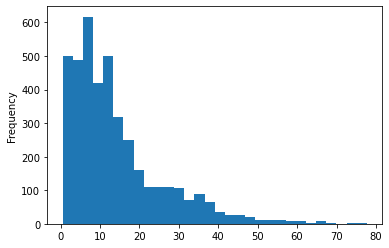

In [21]:
# Check the kWhDelivered when the doneChargingTime is null to avoid station issues
data_charge[data_charge["doneChargingTime"].isnull()]["kWhDelivered"].plot.hist(bins=30)

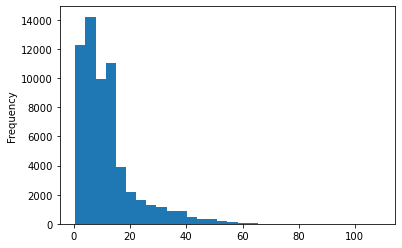

In [20]:
data_charge[data_charge["doneChargingTime"].notnull()]["kWhDelivered"].plot.hist(bins=30)

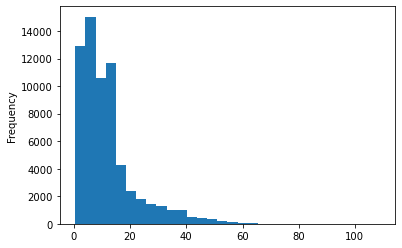

In [22]:
# Check the kWhDelivered
data_charge["kWhDelivered"].plot.hist(bins=30)

In [23]:
# Checmk for inplausible data
data_charge[data_charge["kWhDelivered"] <= 0]

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs,endChargingTime


# Feature Engineering

In [24]:
# Add a column "chargingDurationMin" that covers information how long the cars took to charge (endChargingTime-connectionTime)
data_charge["chargingDurationMin"] = (
    data_charge["endChargingTime"] - data_charge["connectionTime"]
).dt.total_seconds() / 60

In [25]:
# Add a column "blockingDurationMin" that covers information how long the cars stayed on a slot without charging (disconnectTime-endChargingTime)
data_charge["blockingDurationMin"] = (
    data_charge["disconnectTime"] - data_charge["endChargingTime"]
).dt.total_seconds() / 60

In [26]:
# Check if disconnectTime is larger or equal than doneChargingTime and this should be larger or equal than connection time
valid_records = data_charge[
    (data_charge["disconnectTime"] >= data_charge["endChargingTime"])
    & (data_charge["endChargingTime"] >= data_charge["connectionTime"])
]

valid_count = len(valid_records)
total_count = len(data_charge)

print(f"Amount valid records: {valid_count}")
print(f"Amount records: {total_count}")
print(f"Valid records ratio: {valid_count / total_count * 100:.2f}%")

invalid_records = data_charge[
    ~(
        (data_charge["disconnectTime"] >= data_charge["endChargingTime"])
        & (data_charge["endChargingTime"] >= data_charge["connectionTime"])
    )
]

Amount valid records: 60623
Amount records: 65037
Valid records ratio: 93.21%


In [27]:
num_negative_charging_duration = len(data_charge[data_charge["chargingDurationMin"] < 0])
num_negative_blocking_duration = len(data_charge[data_charge["blockingDurationMin"] < 0])
print(
    f"Number of records with negative charging {num_negative_charging_duration} and blocking durations: {num_negative_blocking_duration}"
)

Number of records with negative charging 27 and blocking durations: 4387


In [28]:
# Drop the records with negative charging duration
data_charge = data_charge[data_charge["chargingDurationMin"] >= 0]

In [29]:
# Filter records where blockingDurationMin is less than 0
negative_blocking_duration = data_charge[data_charge["blockingDurationMin"] < 0]
negative_blocking_duration.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,4387.000000,4387.000000,4387.000000,3329.000000,4387.000000,4387.000000
mean,4791.890586,14.239556,1.268977,1458.393812,261.420910,-0.933618
std,3401.268410,12.575748,0.443478,1532.613614,243.599541,1.271500
min,0.000000,0.508000,1.000000,22.000000,4.216667,-59.933333
25%,1850.000000,5.379000,1.000000,410.000000,109.875000,-0.983333
50%,4296.000000,11.161000,1.000000,832.000000,205.850000,-0.966667
75%,7407.500000,19.239500,2.000000,2052.000000,356.950000,-0.950000
max,15135.000000,108.797242,2.000000,17097.000000,9013.966667,-0.016667


=> We need a time buffer because we have some measurement problems.
Possible reasons: The finished charge sensor only responds at 30Hz - 60Hz. Therefore some measurement deviations are ok.
Sources that prove this are the following:
1) https://blog.chargemap.com/de/daten-von-ladestationen-auf-chargemap-wie-echtzeit-funktioniert/ [accessed 16.01.2025]
2) https://www.cloudflight.io/de/blog/iot-netzwerke-breites-spektrum-und-offene-fragen/ [accessed 16.01.2025]

In [31]:
data_charge = data_charge[data_charge["blockingDurationMin"] >= -1]

In [32]:
# Set negative blockingDurationMin that is less than one minute to zero
data_charge.loc[
    (data_charge["blockingDurationMin"] < 0) & (data_charge["blockingDurationMin"] >= -1),
    "blockingDurationMin",
] = 0

# Further Outlier Analysis

In [33]:
# Get a brief overview
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,64033.000000,64033.000000,64033.000000,46982.000000,64033.000000,64033.000000
mean,4633.873175,11.682768,1.486843,1828.868673,215.404003,162.791712
std,3542.968561,10.219610,0.499831,2664.863619,189.058547,237.017809
min,0.000000,0.501000,1.000000,1.000000,0.000000,0.000000
25%,1815.000000,5.051000,1.000000,438.000000,94.800000,0.133333
50%,3858.000000,9.068000,1.000000,826.000000,166.933333,80.200000
75%,6779.000000,14.075000,2.000000,1813.000000,290.333333,284.350000
max,15291.000000,108.797242,2.000000,19923.000000,12000.950000,9367.283333


In [227]:
data_charge[data_charge["kWhDelivered"] > 80]

,Unnamed: 0,id,connectionTime,disconnectTime,doneChargingTime,kWhDelivered,sessionID,siteID,spaceID,stationID,timezone,userID,userInputs,endChargingTime,chargingDurationMin,blockingDurationMin
18641,4338,610c829df9af8b0580e98730,2021-07-20 15:16:54-07:00,2021-07-21 08:18:03-07:00,2021-07-21 08:19:00-07:00,108.797242,1_1_193_829_2021-07-20 18:27:33.500144,1,AG-1F03,1-1-193-829,America/Los_Angeles,378.0,"[{'WhPerMile': 258, 'kWhRequested': 35.088, 'm...",2021-07-21 08:19:00-07:00,1022.100000,0.0
18643,4340,610c829df9af8b0580e98732,2021-07-20 15:16:56-07:00,2021-07-21 08:18:16-07:00,2021-07-21 08:19:13-07:00,89.362732,1_1_194_818_2021-07-20 13:54:47.875453,1,AG-1F14,1-1-194-818,America/Los_Angeles,481.0,"[{'WhPerMile': 360, 'kWhRequested': 86.4, 'mil...",2021-07-21 08:19:13-07:00,1022.283333,0.0


The max kWhDelivered, chargingDurationMin and blockingDurationMin seem to be suspect! Maybe there are outliers in the dataset. Lets check if such high values for kWhDelivered are even technically possible.

After checking the EV-Database (https://ev-database.org/de/cheatsheet/useable-battery-capacity-electric-car) (Accessed 22.11.2024) the mean usable battery capacity is around 72 kWh, while the highest usable battery capacity is 123 kWh. So from a technical and contextual view, values such as 108.79 are possible in kWhDelivered column.

Since our dataset only covers two datapoints which deviate a lot from the other samples, our model would not be able to learn this pattern. In addition we would also not be able to test how our model performs which such high kWhDelivered.

In [228]:
data_charge = data_charge.drop(data_charge[data_charge["kWhDelivered"] > 80].index)

Now, let us continue with the chargingDurationMin. According to Shell, a charging session can last up to 14 hours (https://www.shell.de/geschaeftskunden/shell-card-tankkarten/shell-card-blog/ladezeit-e-auto.html last accessed: 16.01.2025). So we are going to check how many overreach it and drop them

In [229]:
threshold_minutes = 14 * 60

# Count the records with chargingDurationMin greater than 14 hours
num_over_14_hours = len(data_charge[data_charge["chargingDurationMin"] > threshold_minutes])
print(f"Number of records with charging duration over 14 hours: {num_over_14_hours}")

# Drop the records with chargingDurationMin greater than 14 hours
data_charge = data_charge[data_charge["chargingDurationMin"] <= threshold_minutes]

Number of records with charging duration over 14 hours: 210


In [230]:
data_charge.describe()

,Unnamed: 0,kWhDelivered,siteID,userID,chargingDurationMin,blockingDurationMin
count,63821.000000,63821.000000,63821.000000,46891.000000,63821.000000,63821.000000
mean,4632.010811,11.658527,1.485593,1828.737263,210.899313,161.938809
std,3541.370817,10.187106,0.499796,2664.850578,154.342325,229.781897
min,0.000000,0.501000,1.000000,1.000000,0.000000,0.000000
25%,1815.000000,5.045000,1.000000,438.000000,94.533333,0.133333
50%,3855.000000,9.042000,1.000000,826.000000,166.183333,80.333333
75%,6777.000000,14.059000,2.000000,1813.000000,288.683333,284.350000
max,15291.000000,77.700000,2.000000,19923.000000,838.583333,9367.283333


## Find time gaps in the timeseries

In [ ]:
tmp_dc = data_charge[["connectionTime"]]
tmp_dc = tmp_dc.sort_values(by="connectionTime")


tmp_dc["date"] = tmp_dc["connectionTime"].dt.date
tmp_dc["days_gap"] = tmp_dc["date"].diff()
gaps = tmp_dc[tmp_dc["days_gap"] > pd.Timedelta(days=1)]
gaps["end_date"] = gaps["connectionTime"]
gaps["start_date"] = gaps["end_date"] - pd.to_timedelta(gaps["days_gap"], unit="days")
gaps.sort_values(by="days_gap", ascending=False)

c:\Users\janos\anaconda3\envs\JHNLPmitNLTK\lib\site-packages\ipykernel_launcher.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  import sys
c:\Users\janos\anaconda3\envs\JHNLPmitNLTK\lib\site-packages\ipykernel_launcher.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if __name__ == '__main__':


,connectionTime,date,days_gap,end_date,start_date
5049,2020-11-18 12:51:21-08:00,2020-11-18,107 days,2020-11-18 12:51:21-08:00,2020-08-03 13:51:21-07:00
4101,2020-05-26 05:47:29-07:00,2020-05-26,4 days,2020-05-26 05:47:29-07:00,2020-05-22 05:47:29-07:00
4167,2020-06-01 05:46:28-07:00,2020-06-01,3 days,2020-06-01 05:46:28-07:00,2020-05-29 05:46:28-07:00
14121,2019-12-26 04:41:44-08:00,2019-12-26,2 days,2019-12-26 04:41:44-08:00,2019-12-24 04:41:44-08:00
3814,2020-04-20 05:51:09-07:00,2020-04-20,2 days,2020-04-20 05:51:09-07:00,2020-04-18 05:51:09-07:00


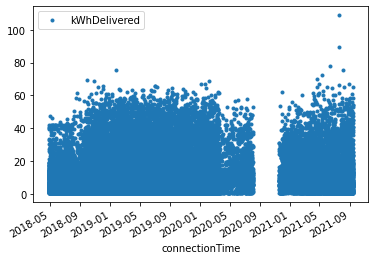

In [47]:
data_charge[["kWhDelivered", "connectionTime"]].set_index("connectionTime").plot(style=".")

Explore now the weather dataset

In [48]:
data_weather.head(3)

,city,timestamp,temperature,cloud_cover,cloud_cover_description,pressure,windspeed,precipitation,felt_temperature
0,Burbank,2018-01-01 08:53:00,9.0,33.0,Fair,991.75,9.0,0.0,8.0
1,Burbank,2018-01-01 09:53:00,9.0,33.0,Fair,992.08,0.0,0.0,9.0
2,Burbank,2018-01-01 10:53:00,9.0,21.0,Haze,992.08,0.0,0.0,9.0


In [49]:
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   city                     29244 non-null  object 
 1   timestamp                29244 non-null  object 
 2   temperature              29219 non-null  float64
 3   cloud_cover              29224 non-null  float64
 4   cloud_cover_description  29224 non-null  object 
 5   pressure                 29236 non-null  float64
 6   windspeed                29158 non-null  float64
 7   precipitation            29244 non-null  float64
 8   felt_temperature         29218 non-null  float64
dtypes: float64(6), object(3)
memory usage: 2.0+ MB


In [50]:
data_weather.describe()

,temperature,cloud_cover,pressure,windspeed,precipitation,felt_temperature
count,29219.000000,29224.000000,29236.000000,29158.000000,29244.000000,29218.000000
mean,17.885622,30.107993,986.879400,8.566568,0.059360,17.731433
std,6.454604,5.400388,3.607065,6.699889,0.471682,6.321100
min,2.000000,4.000000,971.000000,0.000000,0.000000,0.000000
25%,13.000000,26.000000,984.500000,6.000000,0.000000,13.000000
50%,17.000000,33.000000,986.480000,7.000000,0.000000,17.000000
75%,22.000000,34.000000,989.110000,13.000000,0.000000,22.000000
max,46.000000,47.000000,999.650000,57.000000,18.540000,42.000000


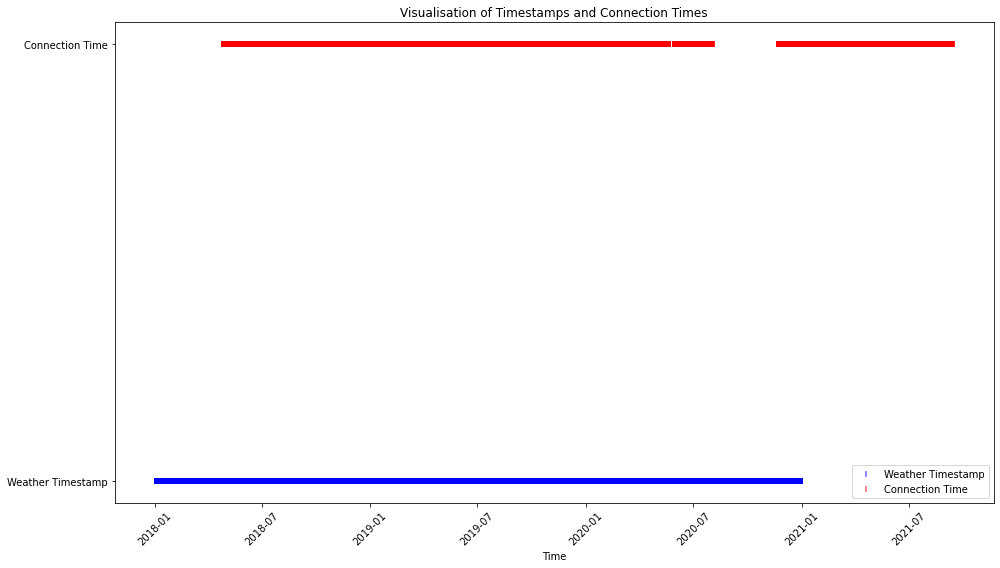

In [51]:
data_weather["timestamp"] = pd.to_datetime(data_weather["timestamp"])
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])

data_weather = data_weather.sort_values(by="timestamp")
data_charge = data_charge.sort_values(by="connectionTime")

plt.figure(figsize=(14, 8))

plt.scatter(
    data_weather["timestamp"],
    [1] * len(data_weather),
    marker="|",
    color="b",
    alpha=0.6,
    label="Weather Timestamp",
)

plt.scatter(
    data_charge["connectionTime"],
    [2] * len(data_charge),
    marker="|",
    color="r",
    alpha=0.6,
    label="Connection Time",
)

plt.title("Visualisation of Timestamps and Connection Times")
plt.xlabel("Time")
plt.yticks([1, 2], ["Weather Timestamp", "Connection Time"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend()
plt.show()

#### Insight:
For specific charging records (their timestamp), there are no weather data records available in the weather dataset. Therefore, we tackle this problem by adding the missing weather data from the external source "visualcrossing" (https://www.visualcrossing.com/weather/weather-data-services). 

In [52]:
additional_weather_data = pd.read_csv("../data/additional_weather_data.csv")
print(additional_weather_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6167 entries, 0 to 6166
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              6167 non-null   object 
 1   datetime          6167 non-null   object 
 2   temp              6167 non-null   float64
 3   feelslike         6167 non-null   float64
 4   dew               6167 non-null   float64
 5   humidity          6167 non-null   float64
 6   precip            6167 non-null   float64
 7   precipprob        6167 non-null   int64  
 8   preciptype        77 non-null     object 
 9   snow              6167 non-null   int64  
 10  snowdepth         6167 non-null   float64
 11  windgust          6167 non-null   float64
 12  windspeed         6167 non-null   float64
 13  winddir           6167 non-null   float64
 14  sealevelpressure  6167 non-null   float64
 15  cloudcover        6167 non-null   float64
 16  visibility        6167 non-null   float64


In [53]:
additional_weather_data.head()

,name,datetime,temp,feelslike,dew,humidity,precip,precipprob,preciptype,snow,...,sealevelpressure,cloudcover,visibility,solarradiation,solarenergy,uvindex,severerisk,conditions,icon,stations
0,Burbank,2021-01-01T00:00:00,10.4,10.4,-1.7,43.09,0.0,0,NaN,0,...,1015.0,0.0,16.0,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
1,Burbank,2021-01-01T01:00:00,15.2,15.2,-5.1,24.18,0.0,0,NaN,0,...,1015.0,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
2,Burbank,2021-01-01T02:00:00,15.1,15.1,-5.1,24.47,0.0,0,NaN,0,...,1015.3,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
3,Burbank,2021-01-01T03:00:00,14.0,14.0,-5.2,26.18,0.0,0,NaN,0,...,1015.3,0.0,15.4,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."
4,Burbank,2021-01-01T04:00:00,14.5,14.5,-6.0,23.72,0.0,0,NaN,0,...,1015.4,0.0,15.5,0.0,0.0,0,NaN,Clear,clear-night,"KVNY,KBUR,KCQT,72288623130,72288023152,7228749..."


In [55]:
# Show all column names of the data sets
print("Column names in 'data_weather'-dataset:")
print(data_weather.columns.tolist())

print("\n Column names in'additional_weather_data'-dataset:")
print(additional_weather_data.columns.tolist())

Column names in 'data_weather'-dataset:
['city', 'timestamp', 'temperature', 'cloud_cover', 'cloud_cover_description', 'pressure', 'windspeed', 'precipitation', 'felt_temperature']

 Column names in'additional_weather_data'-dataset:
['name', 'datetime', 'temp', 'feelslike', 'dew', 'humidity', 'precip', 'precipprob', 'preciptype', 'snow', 'snowdepth', 'windgust', 'windspeed', 'winddir', 'sealevelpressure', 'cloudcover', 'visibility', 'solarradiation', 'solarenergy', 'uvindex', 'severerisk', 'conditions', 'icon', 'stations']


In [56]:
data_weather.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 29244 entries, 0 to 29243
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   city                     29244 non-null  object        
 1   timestamp                29244 non-null  datetime64[ns]
 2   temperature              29219 non-null  float64       
 3   cloud_cover              29224 non-null  float64       
 4   cloud_cover_description  29224 non-null  object        
 5   pressure                 29236 non-null  float64       
 6   windspeed                29158 non-null  float64       
 7   precipitation            29244 non-null  float64       
 8   felt_temperature         29218 non-null  float64       
dtypes: datetime64[ns](1), float64(6), object(2)
memory usage: 2.2+ MB


In [58]:
# Check columnnames
print("Columnnames in the 'data_weather'-dataset:", data_weather.columns.tolist())
print(
    "Columnnames in the 'additional_weather_data'-dataset:",
    additional_weather_data.columns.tolist(),
    "\n",
)

# Rename the columns in additional_weather_data
additional_weather_data = additional_weather_data.rename(
    columns={
        "name": "city",
        "datetime": "timestamp",
        "temp": "temperature",
        "feelslike": "felt_temperature",
        "cloudcover": "cloud_cover",
        "sealevelpressure": "pressure",
        "windspeed": "windspeed",
        "precip": "precipitation",
    }
)

# Keep relevant columns of additional_weather_data
additional_weather_data = additional_weather_data[
    [
        "city",
        "timestamp",
        "temperature",
        "felt_temperature",
        "cloud_cover",
        "pressure",
        "windspeed",
        "precipitation",
    ]
]

# Convert the timestamp in both datasets to datetime objecs
# data_weather["timestamp"] = pd.to_datetime(data_weather["timestamp"])
additional_weather_data["timestamp"] = pd.to_datetime(additional_weather_data["timestamp"])

# Complement the missing records by merging the datasets
data_weather_combined = pd.concat(
    [data_weather, additional_weather_data], ignore_index=True
).drop_duplicates(subset=["timestamp"])

data_weather_combined = data_weather_combined.sort_values(by="timestamp").reset_index(drop=True)

# Validate the new datenset
print(data_weather_combined.head())
print(data_weather_combined.tail())

# Save the new dataset
data_weather_combined.to_csv("../data/combined_weather_data.csv", index=False)
print("The complemented dataset was successfuly saved.")

Columnnames in the 'data_weather'-dataset: ['city', 'timestamp', 'temperature', 'cloud_cover', 'cloud_cover_description', 'pressure', 'windspeed', 'precipitation', 'felt_temperature']
Columnnames in the 'additional_weather_data'-dataset: ['city', 'timestamp', 'temperature', 'felt_temperature', 'cloud_cover', 'pressure', 'windspeed', 'precipitation'] 

      city           timestamp  temperature  cloud_cover  \
0  Burbank 2018-01-01 08:53:00          9.0         33.0   
1  Burbank 2018-01-01 09:53:00          9.0         33.0   
2  Burbank 2018-01-01 10:53:00          9.0         21.0   
3  Burbank 2018-01-01 11:53:00          9.0         29.0   
4  Burbank 2018-01-01 12:53:00          8.0         33.0   

  cloud_cover_description  pressure  windspeed  precipitation  \
0                    Fair    991.75        9.0            0.0   
1                    Fair    992.08        0.0            0.0   
2                    Haze    992.08        0.0            0.0   
3           Partly Cloudy

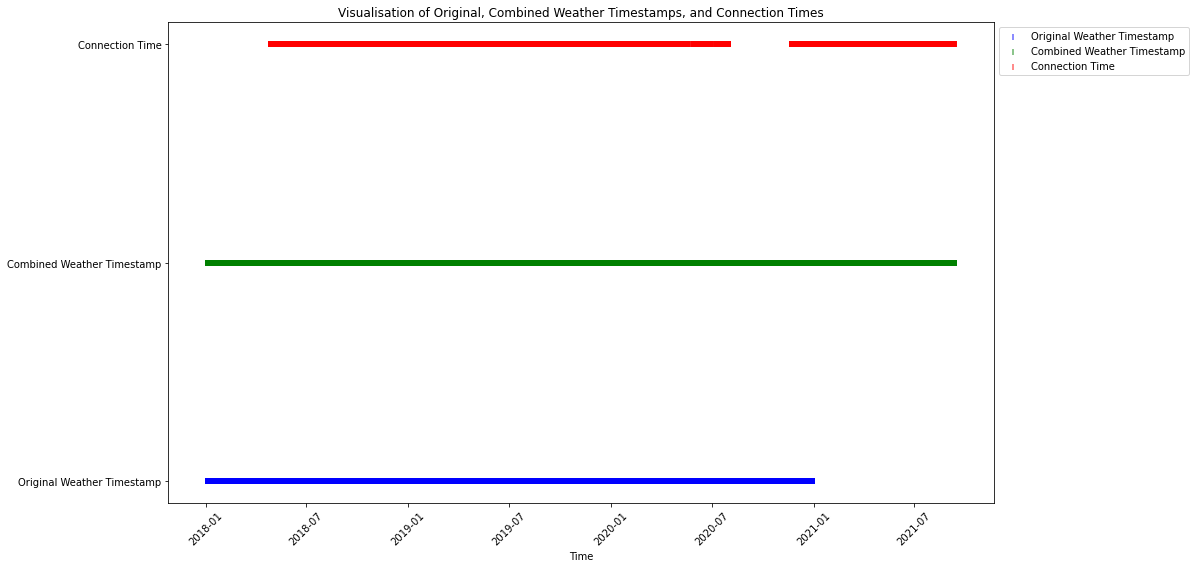

In [242]:
# Plot that the complementation with external data was sucessful



data_weather_combined["timestamp"] = pd.to_datetime(data_weather_combined["timestamp"])
data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])


data_weather = data_weather.sort_values(by="timestamp")
data_weather_combined = data_weather_combined.sort_values(by="timestamp")
data_charge = data_charge.sort_values(by="connectionTime")



# Plot timestamps
plt.figure(figsize=(14, 8))



# Original data (blue)
plt.scatter(

    data_weather["timestamp"],

    [1] * len(data_weather),
    marker="|",
    color="b",

    alpha=0.6,
    label="Original Weather Timestamp",
)



# Complement data (green)
plt.scatter(

    data_weather_combined["timestamp"],

    [1.5] * len(data_weather_combined),
    marker="|",
    color="g",

    alpha=0.6,
    label="Combined Weather Timestamp",
)



# Timestamps (red)
plt.scatter(
    data_charge["connectionTime"],

    [2] * len(data_charge),
    marker="|",
    color="r",

    alpha=0.6,
    label="Connection Time",
)



plt.title("Visualisation of Original, Combined Weather Timestamps, and Connection Times")
plt.xlabel("Time")
plt.yticks(

    [1, 1.5, 2], ["Original Weather Timestamp", "Combined Weather Timestamp", "Connection Time"]

)
plt.xticks(rotation=45)
plt.tight_layout()
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [243]:
data_charge.to_pickle("data_charge_prep.pkl")

# Backup 

In [244]:
# Insights and parsing of user inputs


data_charge["userInputs_parsed"] = data_charge["userInputs"].apply(str)
data_charge["userInputs_parsed"] = data_charge.userInputs.apply(
    lambda x: ast.literal_eval(x) if type(x) == str else []
)
data_charge["userInputs_parsed"].iloc[5]
data_charge["userInputs_parsed_len"] = data_charge["userInputs_parsed"].apply(len)

data_charge["userInputs_parsed_len"].value_counts()
data_charge[data_charge["userInputs_parsed_len"] == 3]["userInputs_parsed"].iloc[0]

[{'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 60,
  'modifiedAt': 'Mon, 07 May 2018 14:38:32 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Mon, 07 May 2018 15:38:18 GMT',
  'userID': 61},
 {'WhPerMile': 400,
  'kWhRequested': 8.0,
  'milesRequested': 20,
  'minutesAvailable': 648,
  'modifiedAt': 'Mon, 07 May 2018 15:40:44 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Tue, 08 May 2018 01:26:18 GMT',
  'userID': 61},
 {'WhPerMile': 400,
  'kWhRequested': 28.0,
  'milesRequested': 70,
  'minutesAvailable': 648,
  'modifiedAt': 'Mon, 07 May 2018 15:41:04 GMT',
  'paymentRequired': True,
  'requestedDeparture': 'Tue, 08 May 2018 01:26:18 GMT',
  'userID': 61}]